# End-to-End Demo (Mitten)

Build the [[150, 30]] mitten code, optimize the `hook_error_free` schedule's layer order
by estimated circuit-level distance, and compare it against the `custom` (depth-12) strategy
in circuit depth and simulated memory performance.

Reference: [arXiv:2607.28795](https://arxiv.org/abs/2607.28795)

In [12]:
import matplotlib.pyplot as plt
import numpy as np
import stim

from quits.circuit import check_overlapping_CX
from quits import ErrorModel, CircuitBuildOptions
from quits.decoder import sliding_window_bposd_circuit_mem
from quits.gf2_util import cyclic, direct_product, symmetric
from quits.qldpc_code import MittenCode
from quits.qldpc_code.mitten import sample_mitten_base_matrices
from quits.simulation import (
    estimate_spacetime_distance,
    get_stim_mem_result,
    spacetime_matrices,
)
from quits.layout import TransversalLayout

In [2]:
# Common parameters
seed = 0
num_rounds = 5
W, F = 3, 1
max_iter, osd_order = 10, 1

ps = [3e-3, 4e-3, 5e-3]
num_trials = [1000, 500, 300]

num_seed_candidates = 10     # hook_error_free layer orders to screen
screen_trials = 100          # BP-OSD trials per distance estimate
circuit_build_options = CircuitBuildOptions()

<a id='build'></a>
### Build the [[150, 30]] mitten code

The paper's flagship instance lives over $G = C_5 \times S_3$ ($|G| = 30$). The base
matrices are drawn with `sample_mitten_base_matrices`, and the code carries the canonical
Theorem-1 conjugate-pair logical basis.

In [10]:
G = direct_product(cyclic(5), symmetric(3))
A, B = sample_mitten_base_matrices(G, np.random.default_rng(2))
code = MittenCode(A, B, G)
print("hz shape:", code.hz.shape, " hx shape:", code.hx.shape)
print("lz shape:", code.lz.shape, " lx shape:", code.lx.shape)
code.verify_css_logicals()

hz shape: (60, 150)  hx shape: (60, 150)
lz shape: (30, 150)  lx shape: (30, 150)


{'css_condition': True,
 'lz_commutes_with_X': True,
 'lx_commutes_with_Z': True,
 'rank_hz': 60,
 'rank_hx': 60,
 'rank_lz': 30,
 'rank_lx': 30,
 'k_expected': 30,
 'lz_independent_mod_Z_stabilizers': True,
 'lx_independent_mod_X_stabilizers': True,
 'rank_hz_plus_lz': 90,
 'rank_hx_plus_lx': 90,
 'dim_ker_hz': 90,
 'dim_ker_hx': 90,
 'hx_plus_lx_spans_ker_hz': True,
 'hz_plus_lz_spans_ker_hx': True,
 'same_logicals_ZX_anticommute': True,
 'different_logicals_ZX_commute': True,
 'all_tests_passed': True}

<a id='depths'></a>
### Circuit depths

- `custom` — the depth-12 interleaved mixed X/Z schedule; 12 is a hard lower bound set by
  the thumb block's total degree.
- `zxcoloration` — quits' generic Tanner-graph edge coloring, depth 18.
- `hook_error_free` — the paper's group-element-layer schedule, depth 24; every layer is a
  permutation between one check block and one data block (one AOD move on an atom array).

In [4]:
for strategy in ("custom", "zxcoloration", "hook_error_free"):
    c = MittenCode(A, B, G)
    circuit = c.build_circuit(strategy=strategy, num_rounds=1)
    assert check_overlapping_CX(circuit) == []
    print(f"{strategy:<18} depth {c.depth:>3}")

No overlapping CX gates found.
custom             depth  12
No overlapping CX gates found.
zxcoloration       depth  18
No overlapping CX gates found.
hook_error_free    depth  24


<a id='seed-search'></a>
### Optimize the hook-error-free schedule seed

The layer *order* within each finger/thumb section never changes the depth or validity of
the `hook_error_free` schedule — but it changes which hook faults exist, and hence the
circuit-level distance. Appendix H.5 of the paper searches over these orders and screens
candidates by estimated circuit-level distance; `build_circuit(strategy="hook_error_free",
seed=...)` draws one candidate order per seed.

For each candidate we compile a two-round memory circuit per basis, convert its
detector-error model into the spacetime pair $(H, L)$ with `spacetime_matrices`, and probe
$\min\{|e| : He = 0,\ Le \neq 0\}$ with `estimate_spacetime_distance` (BP-OSD). The
estimates are randomized **upper bounds** — only the relative comparison is meaningful.
Screening uses the paper's no-idle noise model, since hook faults come from gates.

In [5]:
error_model_screen = ErrorModel(idle_error=0.0, sqgate_error=0.0, tqgate_error=1e-3, spam_error=1e-3)


def screened_distance(strategy, hef_seed=None):
    bounds = []
    for basis in ("Z", "X"):
        c = MittenCode(A, B, G)
        kwargs = {} if hef_seed is None else {"seed": hef_seed}
        circuit = c.build_circuit(
            strategy=strategy,
            error_model=error_model_screen,
            num_rounds=2,
            basis=basis,
            circuit_build_options=circuit_build_options,
            **kwargs,
        )
        H, L = spacetime_matrices(circuit)
        bounds.append(estimate_spacetime_distance(H, L, num_trials=screen_trials, seed=1))
    return tuple(bounds)


candidates = [None] + list(range(num_seed_candidates))
print(f"{'schedule':<34}{'d_circ(Z) <=':>13}{'d_circ(X) <=':>14}{'min':>6}")
screen = {}
for hef_seed in candidates:
    dz, dx = screened_distance("hook_error_free", hef_seed)
    screen[hef_seed] = (dz, dx)
    label = "hook_error_free (default order)" if hef_seed is None else f"hook_error_free (seed={hef_seed})"
    print(f"{label:<34}{dz:>13}{dx:>14}{min(dz, dx):>6}")

dz, dx = screened_distance("custom")
print(f"{'custom (depth 12)':<34}{dz:>13}{dx:>14}{min(dz, dx):>6}")

best_seed = max(screen, key=lambda s: (min(screen[s]), sum(screen[s])))
print(f"\nbest hook_error_free seed: {best_seed}  d_circ bounds {screen[best_seed]}")

schedule                           d_circ(Z) <=  d_circ(X) <=   min
hook_error_free (default order)               6             7     6
hook_error_free (seed=0)                      5             7     5
hook_error_free (seed=1)                      8             7     7
hook_error_free (seed=2)                      8             6     6
hook_error_free (seed=3)                      8             7     7
hook_error_free (seed=4)                      5             6     5
hook_error_free (seed=5)                      5             8     5
hook_error_free (seed=6)                      8             8     8
hook_error_free (seed=7)                      8             8     8
hook_error_free (seed=8)                      5             8     5
hook_error_free (seed=9)                      8             7     7
custom (depth 12)                             7             8     7

best hook_error_free seed: 6  d_circ bounds (8, 8)


<a id='sweep'></a>
### Memory sweep: optimized hook-error-free vs custom

Both strategies run the same code, decoder, and noise model; only the syndrome-extraction
schedule differs.

- Noise: uniform `ErrorModel(p/10, p/10, p, p)` — idling and single-qubit-gate errors are set as rate $p/10$, while two-qubit-gate and SPAM errors are set at rate $p$. Unlike the paper's model, idling noise is included, so qubits idling
  through a longer SE cycle accumulate more faults: the depth-12 `custom` schedule has a
  genuine advantage here. 
- Decoder: sliding-window BP-OSD on the circuit-level detector error model. **In the paper, authors use a new telescoping decoder that brings the logical error rate down by 3-4 orders of magnitude** (see Fig. 9 of arXiv:2607.28795), so the logical error rates here are just for comparing the different circuit construction strategies. 

### Outputs/metrics

- `pL`: logical error rate per experiment (any logical qubit flips).
- `LFR`: logical failure rate per round, $1 - (1 - p_L)^{1/\text{num\_rounds}}$.
- Error bars: simple 95% confidence interval $p_L \pm 1.96\sqrt{p_L(1-p_L)/n}$
  (clipped to $[0, 1]$), mapped through the LFR formula.

In [7]:
to_lfr = lambda x: 1 - (1 - x) ** (1 / num_rounds)


def run_sweep(label, **build_kwargs):
    results = []
    for p, n_shots in zip(ps, num_trials):
        c = MittenCode(A, B, G)
        circuit = c.build_circuit(
            error_model=ErrorModel(p/10, p/10, p, p),
            num_rounds=num_rounds,
            basis="Z",
            circuit_build_options=circuit_build_options,
            **build_kwargs,
        )
        detection_events, observable_flips = get_stim_mem_result(circuit, n_shots, seed=seed)
        logical_pred = sliding_window_bposd_circuit_mem(
            detection_events, circuit, c.hz, c.lz, W, F,
            max_iter=max_iter, osd_order=osd_order, tqdm_on=True,
        )
        fails = int(np.sum((observable_flips - logical_pred).any(axis=1)))
        pL = fails / n_shots
        half_width = 1.96 * np.sqrt(pL * (1 - pL) / n_shots)
        pL_lo, pL_hi = max(pL - half_width, 0.0), min(pL + half_width, 1.0)
        results.append(dict(p=p, n=n_shots, fails=fails, pL=pL,
                            lfr=to_lfr(pL), lfr_lo=to_lfr(pL_lo), lfr_hi=to_lfr(pL_hi)))
        r = results[-1]
        print(f"{label}  p={p:.1e}: {fails}/{n_shots} failures, pL={pL:.4f}, "
              f"LFR/round={r['lfr']:.2e} [{r['lfr_lo']:.2e}, {r['lfr_hi']:.2e}]")
    return results


sweeps = {}
sweeps["custom (depth 12)"] = run_sweep("custom         ", strategy="custom")
hef_kwargs = dict(strategy="hook_error_free")
if best_seed is not None:
    hef_kwargs["seed"] = best_seed
hef_label = f"hook_error_free (depth 24, seed={best_seed})"
sweeps[hef_label] = run_sweep("hook_error_free", **hef_kwargs)

100%|██████████| 1000/1000 [05:52<00:00,  2.83it/s]


custom           p=3.0e-03: 117/1000 failures, pL=0.1170, LFR/round=2.46e-02 [2.02e-02, 2.90e-02]


100%|██████████| 500/500 [03:42<00:00,  2.24it/s]


custom           p=4.0e-03: 153/500 failures, pL=0.3060, LFR/round=7.05e-02 [5.99e-02, 8.15e-02]


100%|██████████| 300/300 [02:28<00:00,  2.01it/s]


...

hook_error_free  p=3.0e-03: 202/1000 failures, pL=0.2020, LFR/round=4.41e-02 [3.82e-02, 5.02e-02]


100%|██████████| 500/500 [05:15<00:00,  1.59it/s]


hook_error_free  p=4.0e-03: 220/500 failures, pL=0.4400, LFR/round=1.09e-01 [9.61e-02, 1.24e-01]


100%|██████████| 300/300 [03:34<00:00,  1.40it/s]

hook_error_free  p=5.0e-03: 218/300 failures, pL=0.7267, LFR/round=2.28e-01 [2.02e-01, 2.59e-01]


<a id='results'></a>
### Results

The figure compares the logical failure rate per round of the two schedules on the same
code with the same decoder. Caveats:

- The circuit-level distance numbers above are randomized upper bounds; only the relative
  comparison between schedules is meaningful.
- The noise model and decoder differ from the paper, so the error rate values are just for comparing the two circuit construction strategies.
- The two schedules apply exactly the same entangling gates; the `custom` schedule's
  advantage below is driven by idle noise accumulated over its shorter SE cycle.

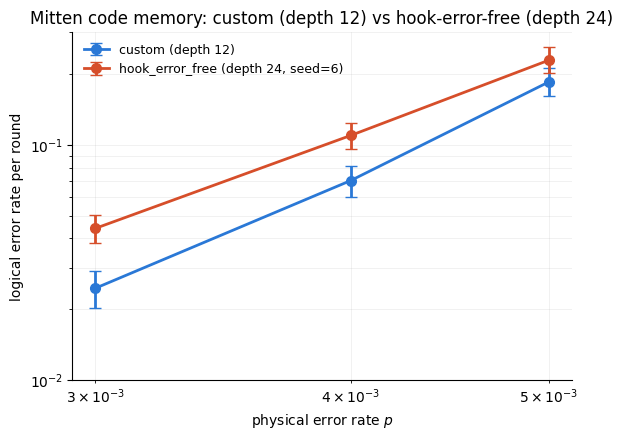

In [9]:
fig, ax = plt.subplots(figsize=(6, 4.5))

colors = {"custom (depth 12)": "#2a78d6", hef_label: "#d64e2a"}
for label, results in sweeps.items():
    p_arr = np.array([r["p"] for r in results])
    lfr = np.array([r["lfr"] for r in results])
    err = np.array([[r["lfr"] - r["lfr_lo"] for r in results],
                    [r["lfr_hi"] - r["lfr"] for r in results]])
    ax.errorbar(p_arr, lfr, yerr=err, color=colors[label], marker="o", markersize=7,
                linewidth=2, capsize=4, label=label)

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("physical error rate $p$")
ax.set_ylabel("logical error rate per round")
ax.set_ylim((1e-2, 3e-1))
ax.set_title("Mitten code memory: custom (depth 12) vs hook-error-free (depth 24)")
ax.grid(True, which="both", alpha=0.25, linewidth=0.5)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=9)
plt.tight_layout()
plt.show()

<a id='visualization'></a>
### Tanner graph visualization

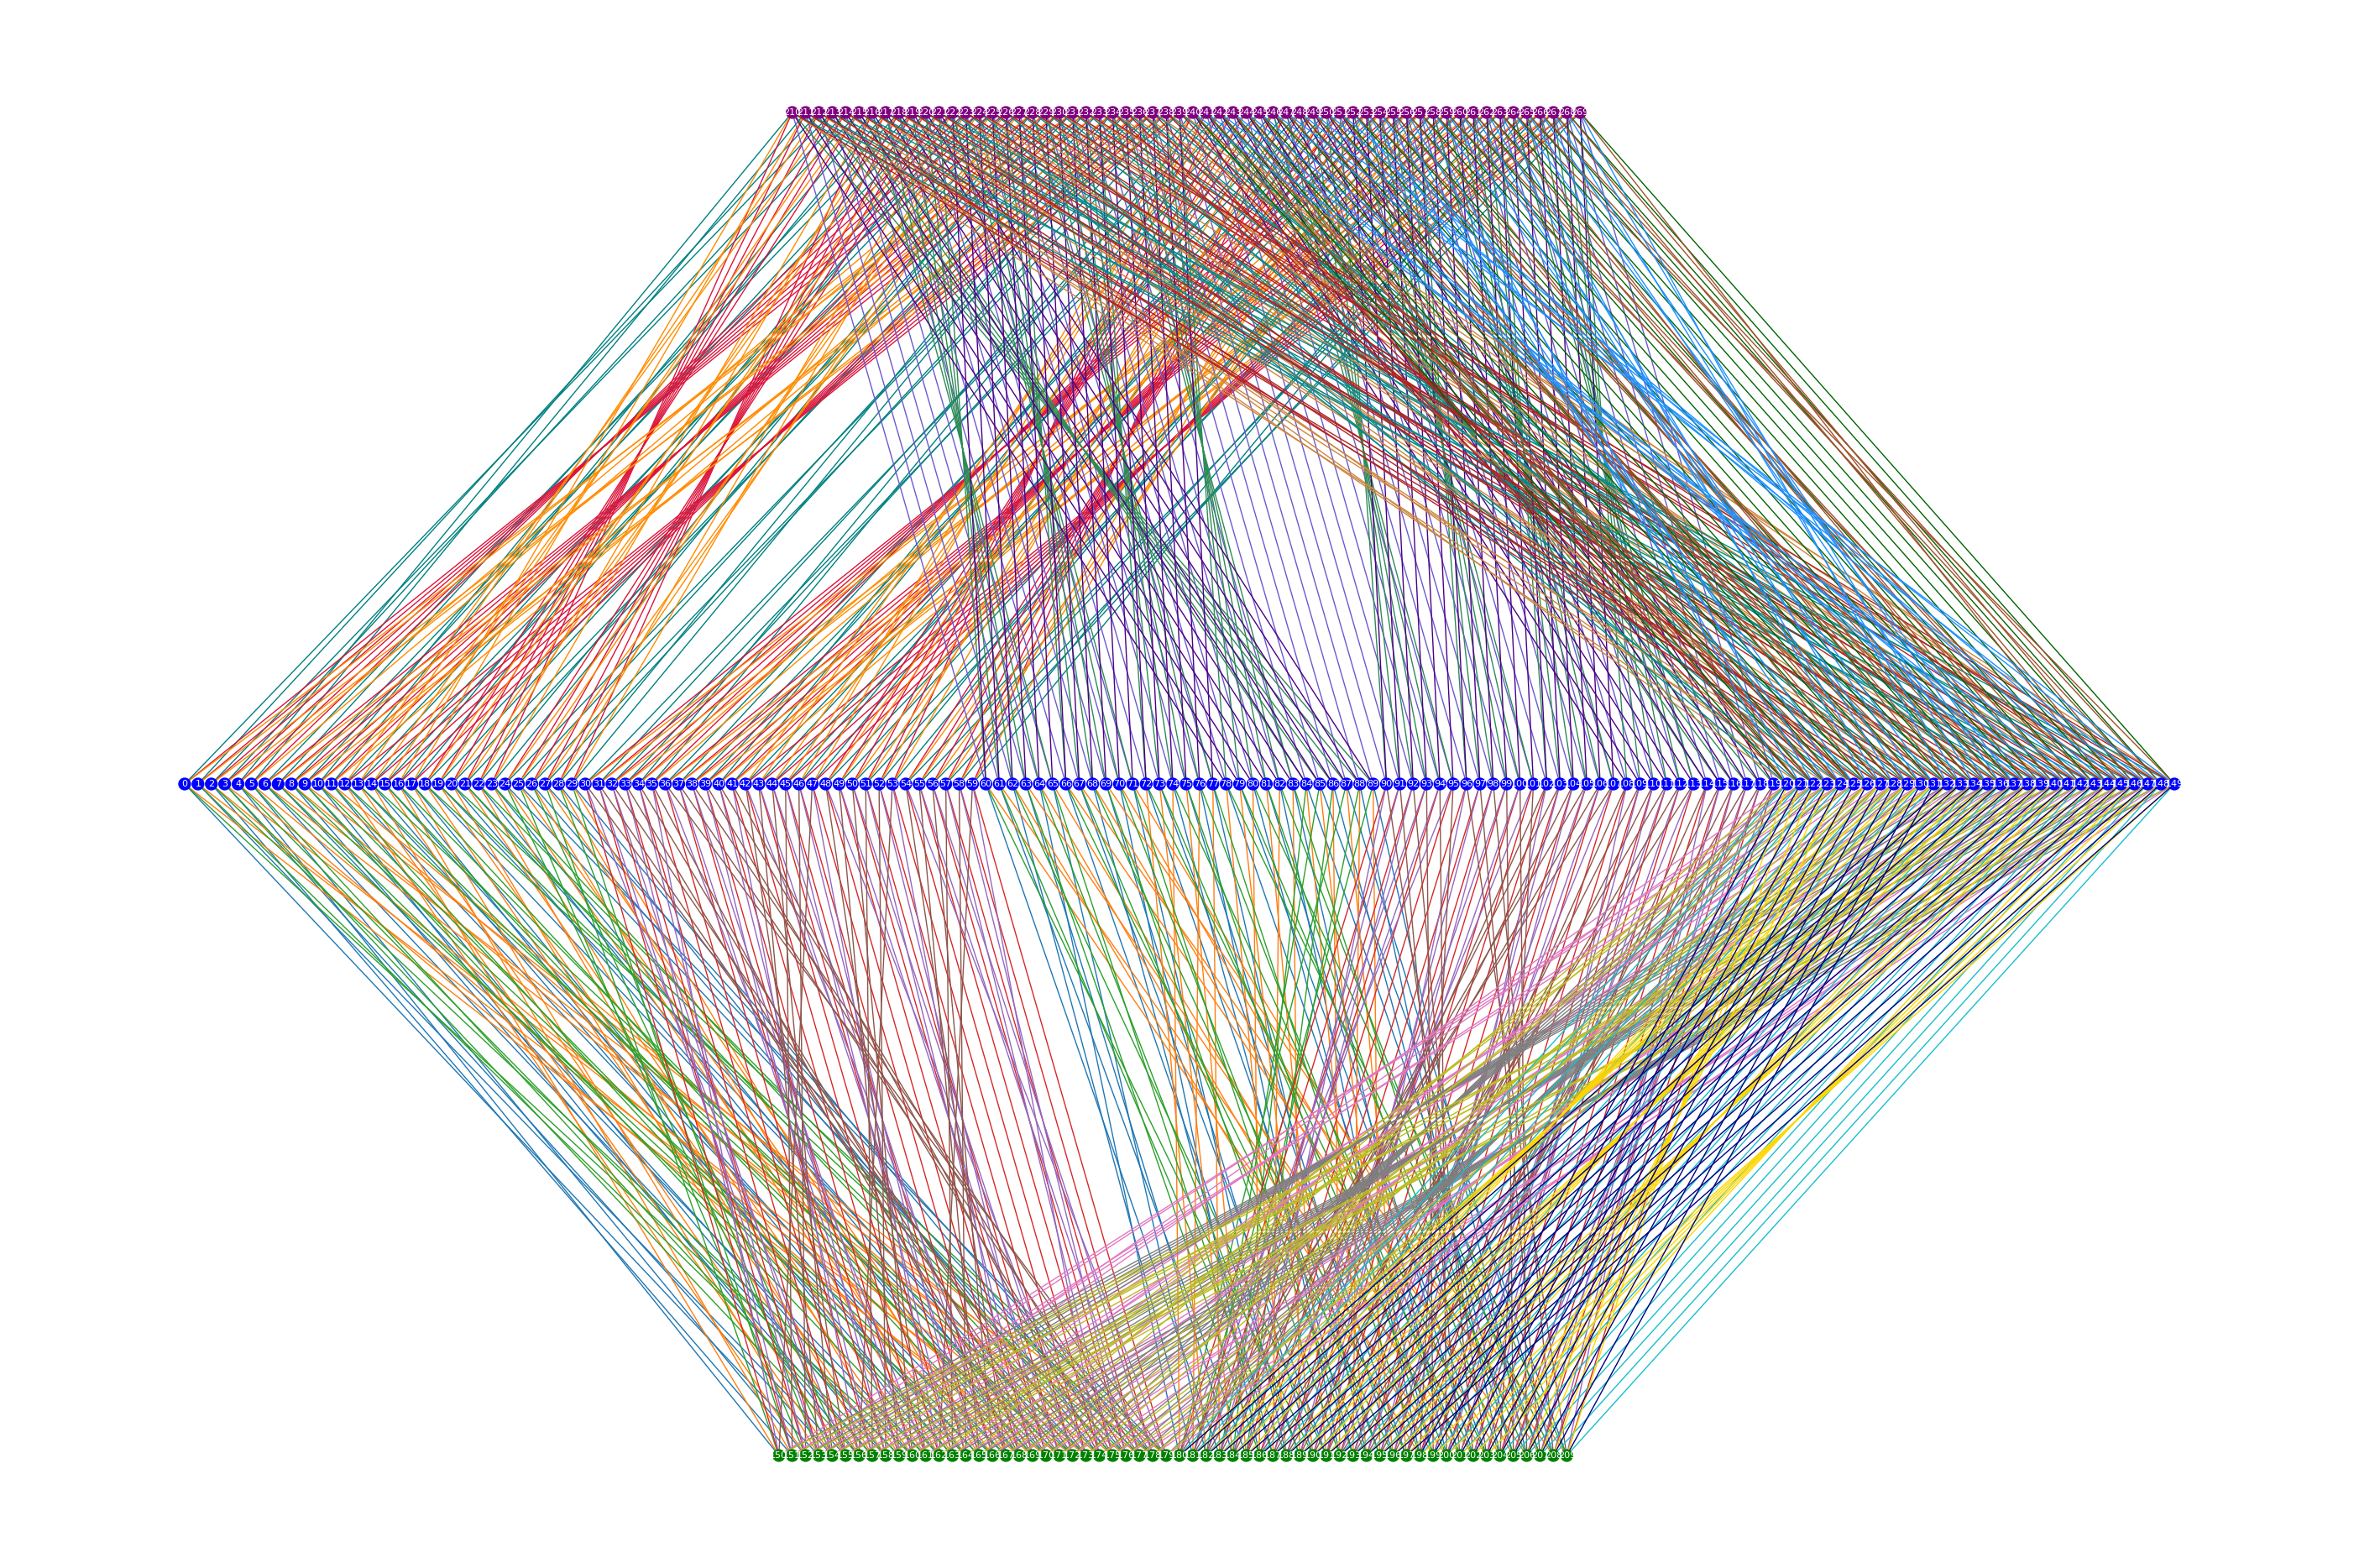

In [ ]:
c = MittenCode(A, B, G)
circuit = c.build_circuit(strategy="hook_error_free")
c.draw_graph(part="all", figsize=(36, 24))